<a href="https://colab.research.google.com/github/samvrudhi-m-d/assesment/blob/main/data_visu_for_medi_track.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned dataset
df = pd.read_csv("/content/meditrack_dataset.csv")

# Set visualization style
sns.set_theme(style="whitegrid")


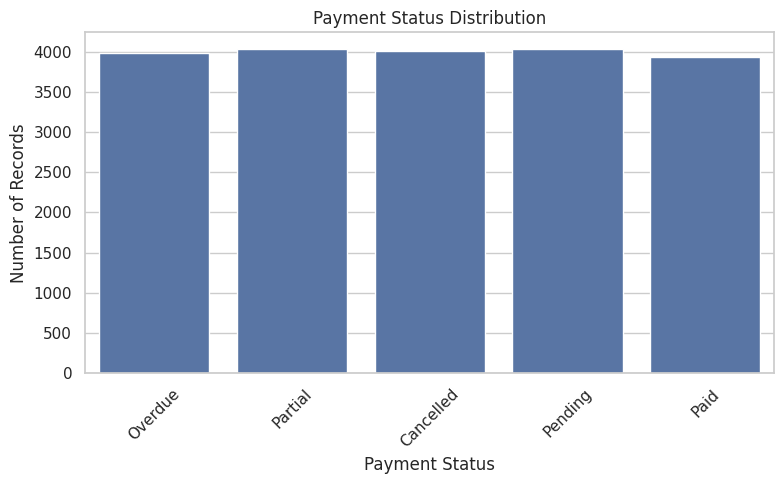

In [2]:
#1
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="PaymentStatus")
plt.title("Payment Status Distribution")
plt.xlabel("Payment Status")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

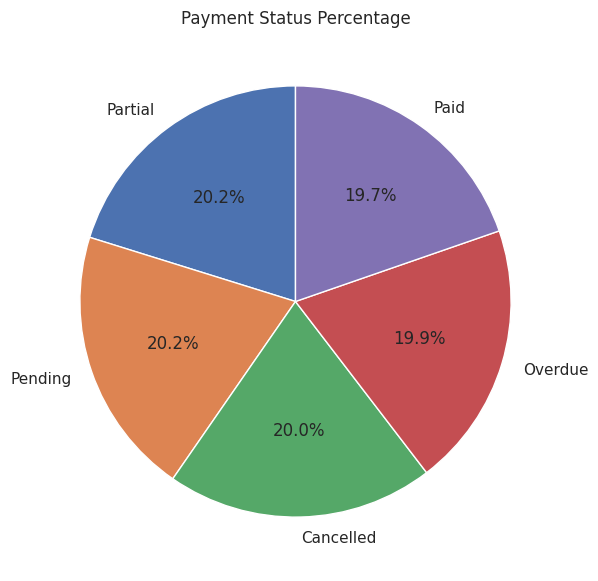

In [3]:
#2
payment_counts = df["PaymentStatus"].value_counts()
plt.figure(figsize=(7, 7))
plt.pie(
    payment_counts.values,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Payment Status Percentage")
plt.show()

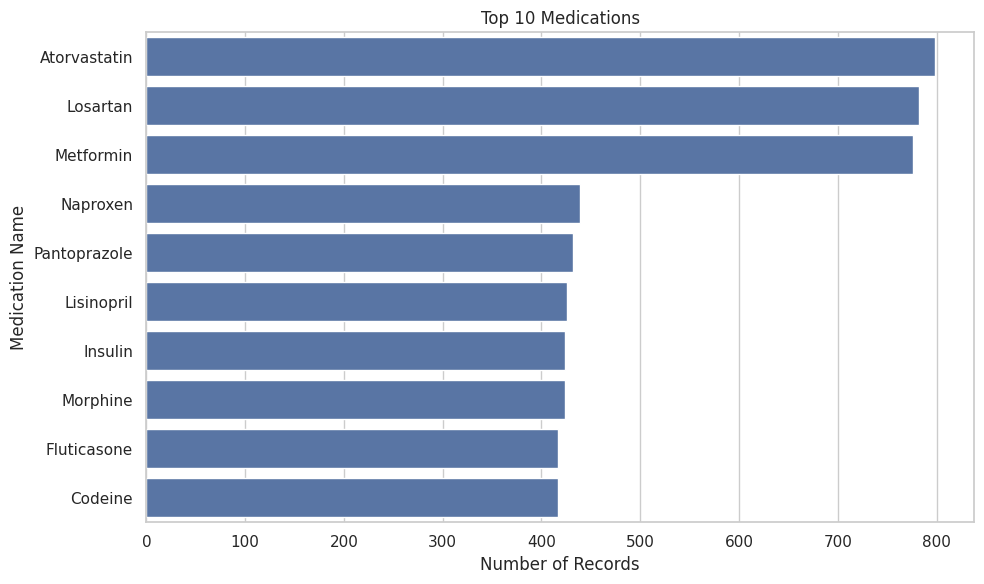

In [4]:
#3
top_medications = df["MedicationName"].value_counts().head(10)
plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_medications.values,
    y=top_medications.index
)

plt.title("Top 10 Medications")
plt.xlabel("Number of Records")
plt.ylabel("Medication Name")

plt.tight_layout()
plt.show()

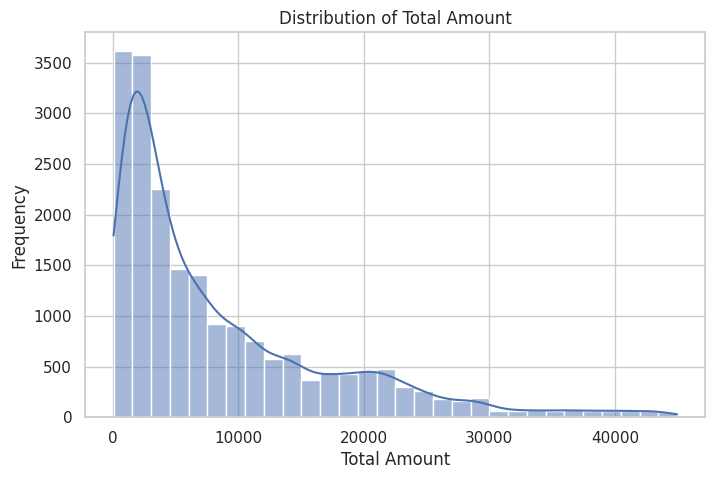

In [5]:
#4
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="TotalAmount",
    bins=30,
    kde=True
)

plt.title("Distribution of Total Amount")
plt.xlabel("Total Amount")
plt.ylabel("Frequency")

plt.show()

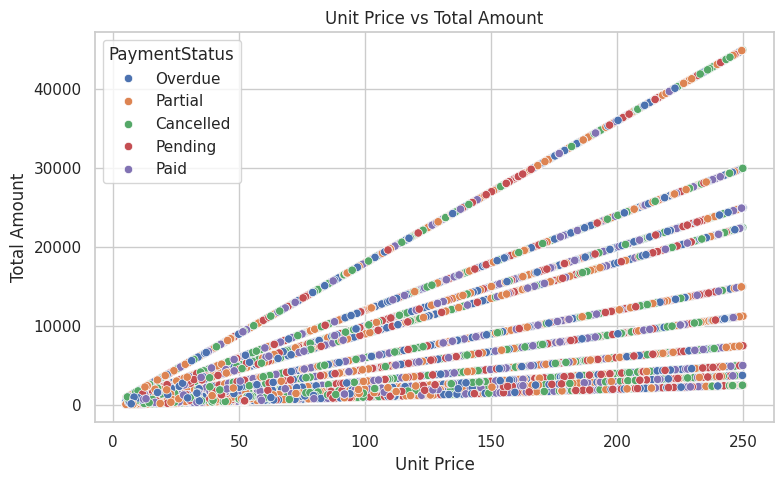

In [6]:
#5
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="UnitPrice",
    y="TotalAmount",
    hue="PaymentStatus"
)

plt.title("Unit Price vs Total Amount")
plt.xlabel("Unit Price")
plt.ylabel("Total Amount")

plt.tight_layout()
plt.show()

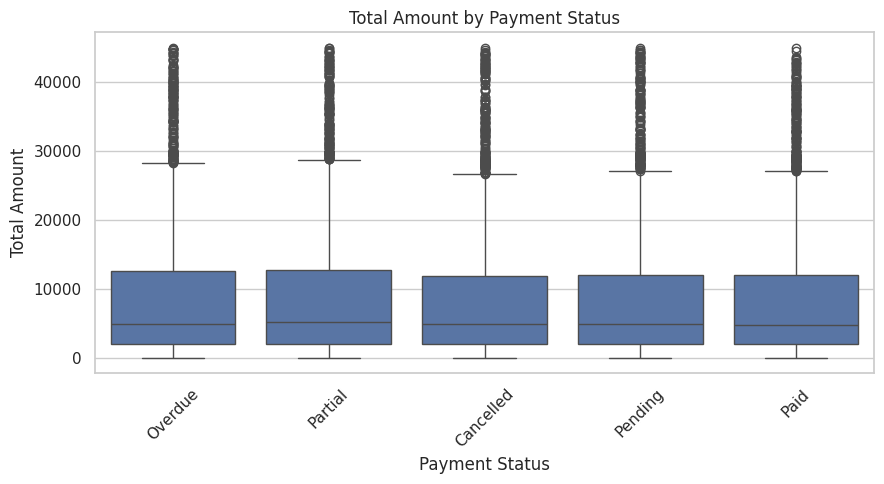

In [7]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="PaymentStatus",
    y="TotalAmount"
)

plt.title("Total Amount by Payment Status")
plt.xlabel("Payment Status")
plt.ylabel("Total Amount")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

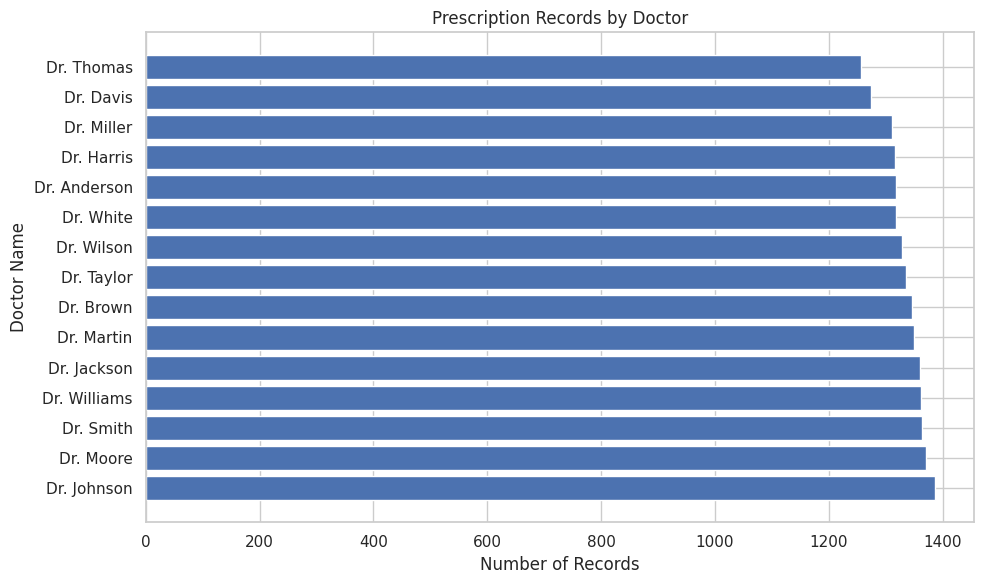

In [8]:
#6
doctor_counts = df["DoctorName"].value_counts()

plt.figure(figsize=(10, 6))

plt.barh(
    doctor_counts.index,
    doctor_counts.values
)

plt.title("Prescription Records by Doctor")
plt.xlabel("Number of Records")
plt.ylabel("Doctor Name")

plt.tight_layout()
plt.show()

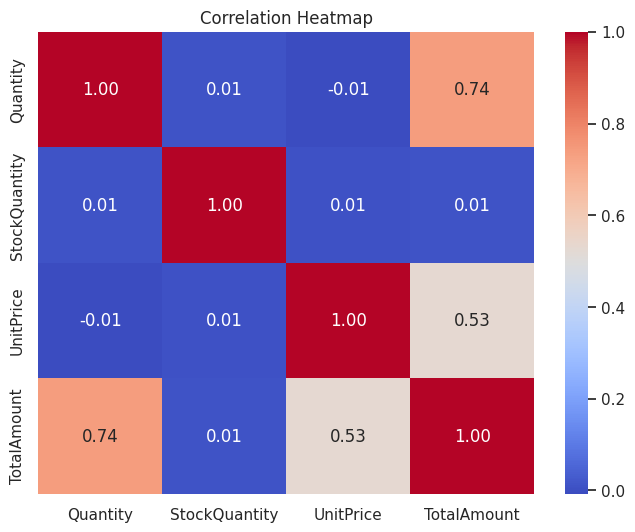

In [9]:
#7
numeric_columns = [
    "Quantity",
    "StockQuantity",
    "UnitPrice",
    "TotalAmount"
]

correlation = df[numeric_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

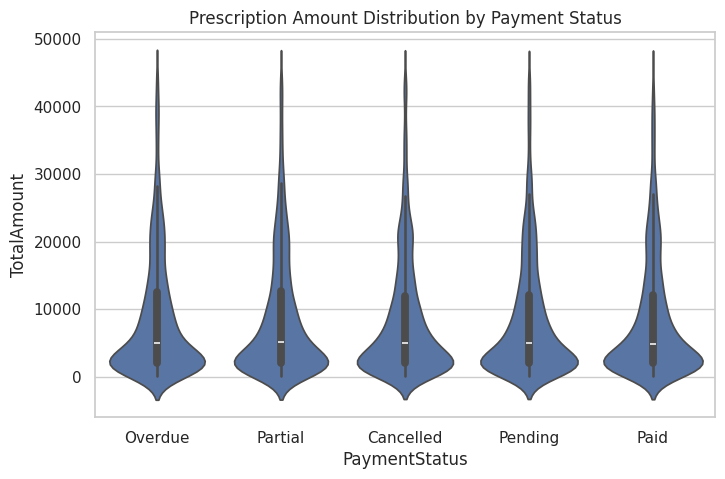

In [10]:
#8,violin plot
plt.figure(figsize=(8, 5))

sns.violinplot(
    data=df,
    x="PaymentStatus",
    y="TotalAmount"
)

plt.title("Prescription Amount Distribution by Payment Status")
plt.show()

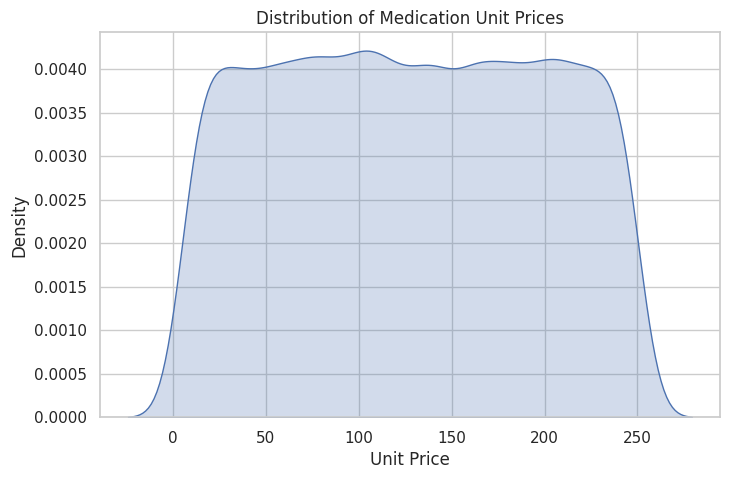

In [11]:
#9,kde plot
plt.figure(figsize=(8, 5))

sns.kdeplot(
    data=df,
    x="UnitPrice",
    fill=True
)

plt.title("Distribution of Medication Unit Prices")
plt.xlabel("Unit Price")

plt.show()

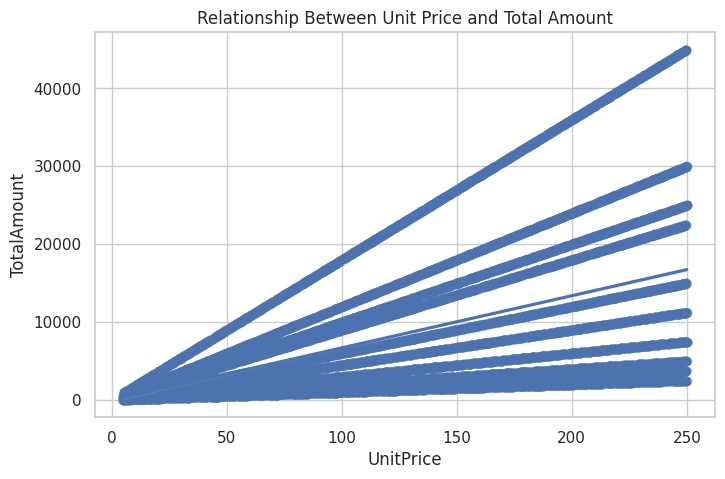

In [12]:
#10,regression plot
plt.figure(figsize=(8, 5))

sns.regplot(
    data=df,
    x="UnitPrice",
    y="TotalAmount",
    scatter_kws={"alpha": 0.4}
)

plt.title("Relationship Between Unit Price and Total Amount")
plt.show()

/tmp/ipykernel_2218/220290442.py:24: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  clean_df["DateIssued"] = pd.to_datetime(


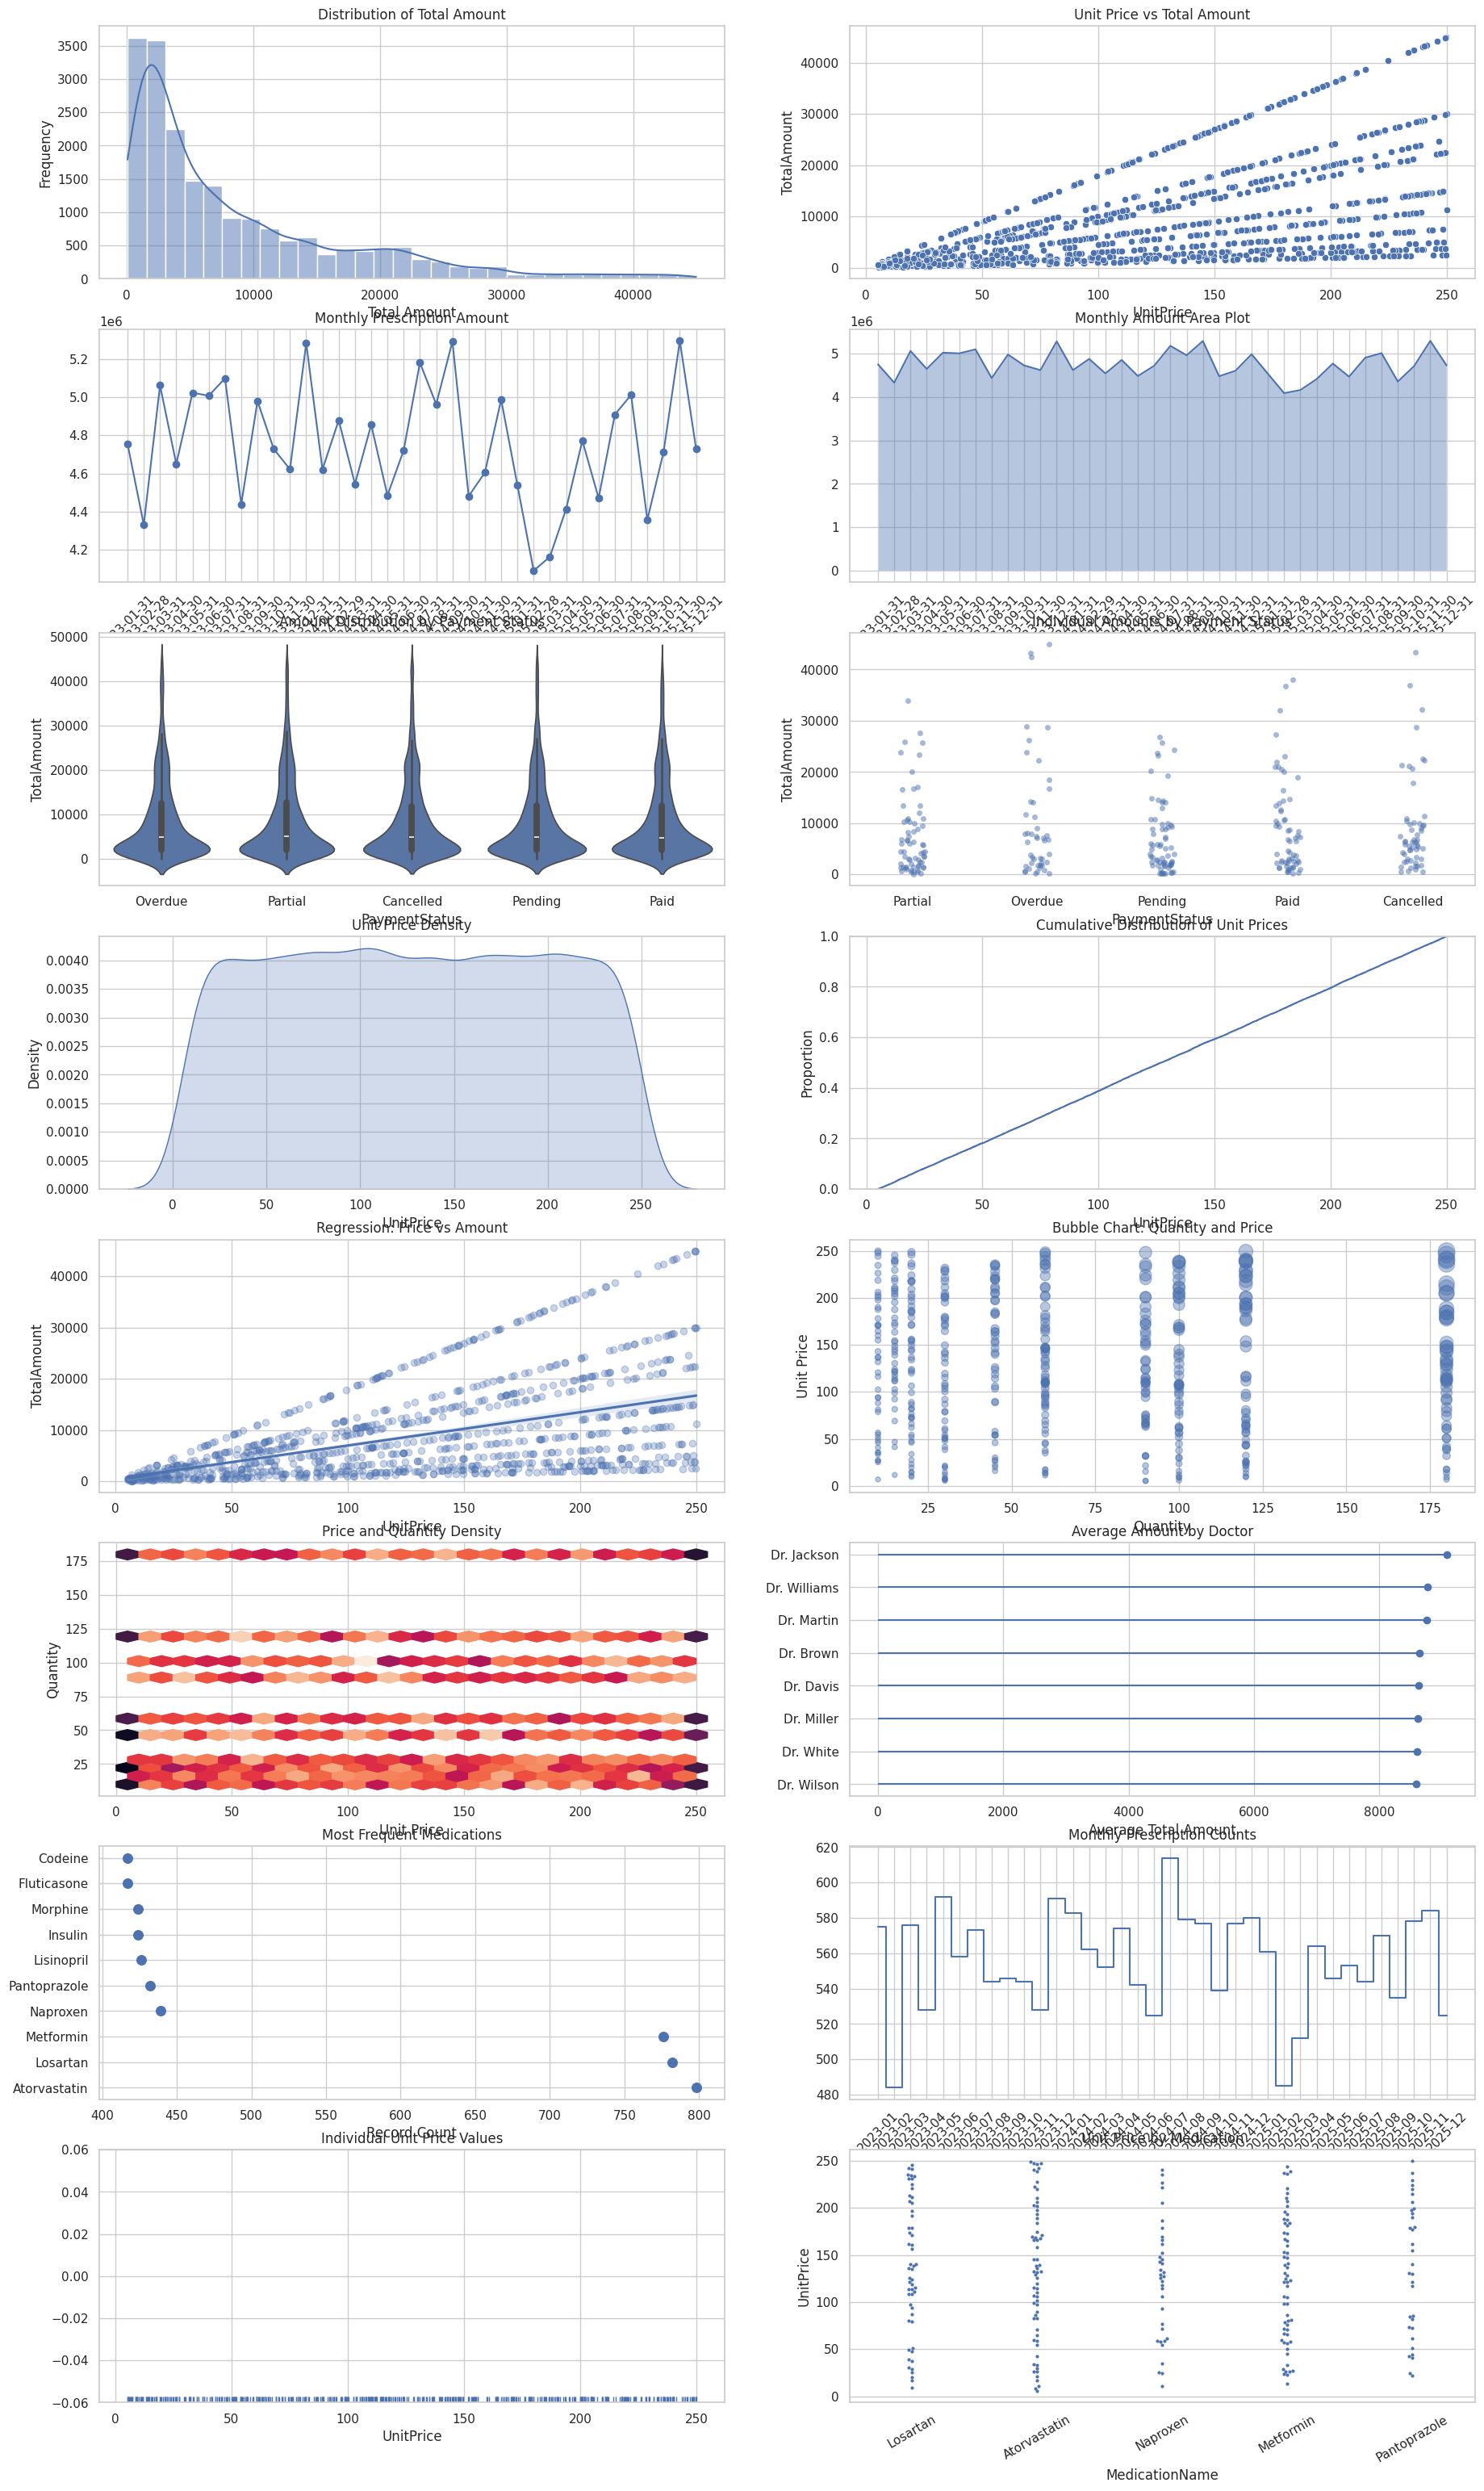

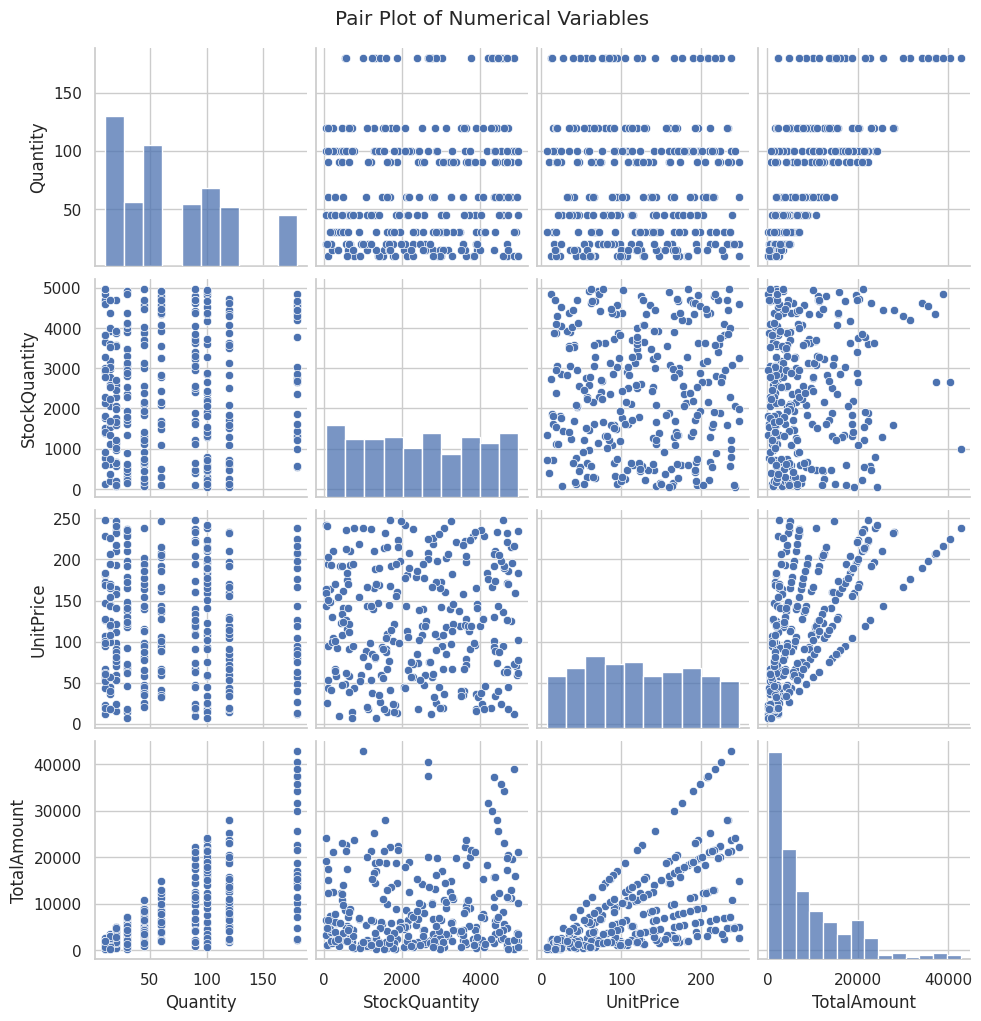

Install squarify to create the treemap.


/tmp/ipykernel_2218/220290442.py:325: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()


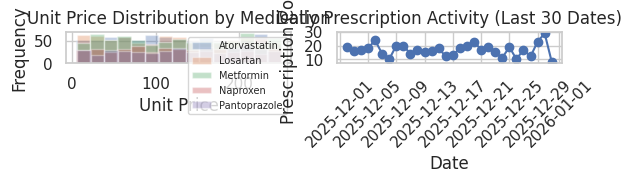

In [13]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset if df is not already loaded
# df = pd.read_csv("cleaned_data.csv")

# Use your existing DataFrame
clean_df = df.copy()

# Convert required columns
numeric_cols = [
    "Quantity", "StockQuantity", "UnitPrice", "TotalAmount"
]

for col in numeric_cols:
    if col in clean_df.columns:
        clean_df[col] = pd.to_numeric(
            clean_df[col], errors="coerce"
        )

if "DateIssued" in clean_df.columns:
    clean_df["DateIssued"] = pd.to_datetime(
        clean_df["DateIssued"], errors="coerce", dayfirst=True
    )

sns.set_theme(style="whitegrid")

# Create space for 20 visualizations
fig = plt.figure(figsize=(22, 48))


# Chart 1 - Distribution of Total Amount
if "TotalAmount" in clean_df.columns:
    plt.subplot(10, 2, 1)
    sns.histplot(
        data=clean_df, x="TotalAmount", bins=30, kde=True
    )
    plt.title("Distribution of Total Amount")
    plt.xlabel("Total Amount")
    plt.ylabel("Frequency")


# Chart 2 - Unit Price vs Total Amount
if {"UnitPrice", "TotalAmount"}.issubset(clean_df.columns):
    plt.subplot(10, 2, 2)
    sns.scatterplot(
        data=clean_df.sample(
            min(1000, len(clean_df)), random_state=42
        ),
        x="UnitPrice", y="TotalAmount"
    )
    plt.title("Unit Price vs Total Amount")


# Chart 3 - Monthly Prescription Amount
if {"DateIssued", "TotalAmount"}.issubset(clean_df.columns):
    plt.subplot(10, 2, 3)
    monthly = (
        clean_df.dropna(subset=["DateIssued", "TotalAmount"])
        .set_index("DateIssued")["TotalAmount"]
        .resample("ME").sum()
    )
    plt.plot(monthly.index.astype(str), monthly.values, marker="o")
    plt.title("Monthly Prescription Amount")
    plt.xticks(rotation=45)


# Chart 4 - Monthly Prescription Area Plot
if {"DateIssued", "TotalAmount"}.issubset(clean_df.columns):
    plt.subplot(10, 2, 4)
    plt.fill_between(
        monthly.index.astype(str),
        monthly.values,
        alpha=0.4
    )
    plt.plot(monthly.index.astype(str), monthly.values)
    plt.title("Monthly Amount Area Plot")
    plt.xticks(rotation=45)


# Chart 5 - Violin Plot by Payment Status
if {"PaymentStatus", "TotalAmount"}.issubset(clean_df.columns):
    plt.subplot(10, 2, 5)
    sns.violinplot(
        data=clean_df,
        x="PaymentStatus",
        y="TotalAmount"
    )
    plt.title("Amount Distribution by Payment Status")


# Chart 6 - Strip Plot
if {"PaymentStatus", "TotalAmount"}.issubset(clean_df.columns):
    plt.subplot(10, 2, 6)
    sample = clean_df.dropna(
        subset=["PaymentStatus", "TotalAmount"]
    ).sample(
        min(300, len(clean_df.dropna(
            subset=["PaymentStatus", "TotalAmount"]
        ))),
        random_state=42
    )
    sns.stripplot(
        data=sample, x="PaymentStatus",
        y="TotalAmount", jitter=True, alpha=0.5
    )
    plt.title("Individual Amounts by Payment Status")


# Chart 7 - KDE Plot
if "UnitPrice" in clean_df.columns:
    plt.subplot(10, 2, 7)
    sns.kdeplot(
        data=clean_df, x="UnitPrice", fill=True
    )
    plt.title("Unit Price Density")


# Chart 8 - ECDF Plot
if "UnitPrice" in clean_df.columns:
    plt.subplot(10, 2, 8)
    sns.ecdfplot(data=clean_df, x="UnitPrice")
    plt.title("Cumulative Distribution of Unit Prices")


# Chart 9 - Regression Plot
if {"UnitPrice", "TotalAmount"}.issubset(clean_df.columns):
    plt.subplot(10, 2, 9)
    sample = clean_df.dropna(
        subset=["UnitPrice", "TotalAmount"]
    ).sample(
        min(1000, len(clean_df.dropna(
            subset=["UnitPrice", "TotalAmount"]
        ))),
        random_state=42
    )
    sns.regplot(
        data=sample, x="UnitPrice", y="TotalAmount",
        scatter_kws={"alpha": 0.3}
    )
    plt.title("Regression: Price vs Amount")


# Chart 10 - Bubble Chart
if {"Quantity", "UnitPrice", "TotalAmount"}.issubset(clean_df.columns):
    plt.subplot(10, 2, 10)
    sample = clean_df.dropna(
        subset=["Quantity", "UnitPrice", "TotalAmount"]
    ).sample(
        min(500, len(clean_df.dropna(
            subset=["Quantity", "UnitPrice", "TotalAmount"]
        ))),
        random_state=42
    )
    sizes = 20 + 200 * (
        sample["TotalAmount"].clip(lower=0) /
        max(sample["TotalAmount"].clip(lower=0).max(), 1)
    )
    plt.scatter(
        sample["Quantity"], sample["UnitPrice"],
        s=sizes, alpha=0.4
    )
    plt.title("Bubble Chart: Quantity and Price")
    plt.xlabel("Quantity")
    plt.ylabel("Unit Price")


# Chart 11 - Hexbin Plot
if {"UnitPrice", "Quantity"}.issubset(clean_df.columns):
    plt.subplot(10, 2, 11)
    sample = clean_df.dropna(
        subset=["UnitPrice", "Quantity"]
    )
    plt.hexbin(
        sample["UnitPrice"], sample["Quantity"],
        gridsize=25, mincnt=1
    )
    plt.title("Price and Quantity Density")
    plt.xlabel("Unit Price")
    plt.ylabel("Quantity")


# Chart 12 - Lollipop Chart
if {"DoctorName", "TotalAmount"}.issubset(clean_df.columns):
    plt.subplot(10, 2, 12)
    doctor = (
        clean_df.groupby("DoctorName")["TotalAmount"]
        .mean().dropna().sort_values().tail(8)
    )
    plt.hlines(doctor.index.astype(str), 0, doctor.values)
    plt.plot(doctor.values, doctor.index.astype(str), "o")
    plt.title("Average Amount by Doctor")
    plt.xlabel("Average Total Amount")


# Chart 13 - Dot Plot of Medications
if "MedicationName" in clean_df.columns:
    plt.subplot(10, 2, 13)
    meds = clean_df["MedicationName"].value_counts().head(10)
    plt.scatter(meds.values, meds.index.astype(str), s=70)
    plt.title("Most Frequent Medications")
    plt.xlabel("Record Count")


# Chart 14 - Step Plot of Monthly Prescriptions
if "DateIssued" in clean_df.columns:
    plt.subplot(10, 2, 14)
    dates = clean_df["DateIssued"].dropna()
    monthly_counts = (
        dates.dt.to_period("M").value_counts().sort_index()
    )
    plt.step(
        monthly_counts.index.astype(str),
        monthly_counts.values,
        where="mid"
    )
    plt.title("Monthly Prescription Counts")
    plt.xticks(rotation=45)


# Chart 15 - Rug Plot
if "UnitPrice" in clean_df.columns:
    plt.subplot(10, 2, 15)
    sns.rugplot(
        data=clean_df.sample(
            min(500, len(clean_df)), random_state=42
        ),
        x="UnitPrice"
    )
    plt.title("Individual Unit Price Values")


# Chart 16 - Swarm Plot for Top Medications
if {"MedicationName", "UnitPrice"}.issubset(clean_df.columns):
    plt.subplot(10, 2, 16)
    top_meds = clean_df["MedicationName"].value_counts().head(5).index
    sample = clean_df[
        clean_df["MedicationName"].isin(top_meds)
    ].dropna(subset=["MedicationName", "UnitPrice"])
    sample = sample.sample(min(250, len(sample)), random_state=42)

    if len(sample) > 0:
        sns.swarmplot(
            data=sample, x="MedicationName",
            y="UnitPrice", size=3
        )
        plt.xticks(rotation=30)
    plt.title("Unit Price by Medication")


# Chart 17 - Pair Plot
# Pair plots create their own figure, so they are generated separately.
numeric_available = [
    col for col in numeric_cols if col in clean_df.columns
]
if len(numeric_available) >= 2:
    pair_data = clean_df[numeric_available].dropna()
    pair_data = pair_data.sample(
        min(300, len(pair_data)), random_state=42
    )
    if len(pair_data) > 1:
        sns.pairplot(pair_data)
        plt.suptitle("Pair Plot of Numerical Variables", y=1.02)
        plt.show()


# Chart 18 - Treemap
# Treemaps create their own figure because they need custom layout.
try:
    import squarify

    if {"MedicationName", "TotalAmount"}.issubset(clean_df.columns):
        treemap_data = (
            clean_df.groupby("MedicationName")["TotalAmount"]
            .sum().dropna().sort_values(ascending=False).head(10)
        )
        treemap_data = treemap_data[treemap_data > 0]

        if len(treemap_data) > 0:
            plt.figure(figsize=(10, 6))
            squarify.plot(
                sizes=treemap_data.values,
                label=treemap_data.index.astype(str),
                alpha=0.8
            )
            plt.title("Treemap: Total Amount by Medication")
            plt.axis("off")
            plt.show()
except ImportError:
    print("Install squarify to create the treemap.")


# Chart 19 - Medication Unit Price Distributions
if {"MedicationName", "UnitPrice"}.issubset(clean_df.columns):
    plt.subplot(10, 2, 19)
    top_meds = clean_df["MedicationName"].value_counts().head(5).index
    for med in top_meds:
        values = clean_df.loc[
            clean_df["MedicationName"] == med, "UnitPrice"
        ].dropna()
        if len(values):
            plt.hist(values, bins=15, alpha=0.35, label=str(med))
    plt.title("Unit Price Distribution by Medication")
    plt.xlabel("Unit Price")
    plt.ylabel("Frequency")
    plt.legend(fontsize=7)


# Chart 20 - Calendar-Style Daily Activity
if "DateIssued" in clean_df.columns:
    plt.subplot(10, 2, 20)
    dates = clean_df["DateIssued"].dropna()
    daily = dates.dt.normalize().value_counts().sort_index()
    if len(daily):
        daily = daily.tail(30)
        plt.plot(daily.index, daily.values, marker="o")
        plt.title("Daily Prescription Activity (Last 30 Dates)")
        plt.xlabel("Date")
        plt.ylabel("Prescription Count")
        plt.xticks(rotation=45)


plt.tight_layout()
plt.show()
